# Score training and calibration with XGBoost

We train one XGBoost classifier per LLM using TF–IDF prompt features, excluding prompt length.
Observed scores are projected onto five levels—0, 0.25, 0.5, 0.75, and 1—and the predicted class probabilities are combined into an expected score.
We save the trained predictors and assess their errors and reliability on the separate calibration partition.

In [4]:
# Load the data
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_DIR = None

for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / "1_data_preparation").is_dir():
        PROJECT_DIR = folder
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from inside the project."
    )

DATA_DIR = (
    PROJECT_DIR
    / "1_data_preparation/data/processed/char_tfidf_50k"
)

train_scores = pd.read_pickle(
    DATA_DIR / "train_scores.pkl"
).astype(float)


## Projecting the scores.

In [5]:
# Most of the scores belong to [0,0.25,0.5,0.75.1]
all_scores = train_scores.to_numpy().ravel()

score_counts = pd.Series(all_scores).value_counts().sort_index()

score_summary = pd.DataFrame({
    "count": score_counts,
    "percent": 100 * score_counts / len(all_scores),
})

score_summary.index.name = "score"

display(score_summary.round(4))

proposed_levels = np.array([0, 0.25, 0.5, 0.75, 1])
outside_levels = ~score_summary.index.isin(proposed_levels)
display(score_summary.loc[outside_levels])

,count,percent
score,,
0.00,93268,38.7165
0.10,99,0.0411
0.20,33,0.0137
0.25,15064,6.2532
0.30,27,0.0112
0.40,25,0.0104
0.50,8075,3.3520
0.60,3,0.0012
0.70,29,0.0120


,count,percent
score,,
0.1,99,0.041096
0.2,33,0.013699
0.3,27,0.011208
0.4,25,0.010378
0.6,3,0.001245
0.7,29,0.012038
0.8,41,0.017020
0.9,84,0.034869


In [6]:
#Projecting scores onto the classes

# Multiply by 4, round to the nearest integer, and store as integers.
train_labels = (train_scores * 4).round().astype("int32")

# Convert those labels back into scores for inspection.
train_scores_projected = train_labels / 4

projection_check = pd.DataFrame({
    "original_score": score_summary.index.to_numpy(),
})

projection_check["class_label"] = (
    (projection_check["original_score"] * 4)
    .round()
    .astype("int32")
)

projection_check["projected_score"] = (
    projection_check["class_label"] / 4
)

class_counts = pd.DataFrame({
    model: train_labels[model].value_counts()
    for model in train_labels.columns
}).reindex(range(5), fill_value=0).fillna(0).astype(int)

class_counts.index.name = "class_label"

# Inspect how original scores map to the five training classes.
display(projection_check)
display(class_counts)

,original_score,class_label,projected_score
0,0.00,0,0.00
1,0.10,0,0.00
2,0.20,1,0.25
3,0.25,1,0.25
4,0.30,1,0.25
5,0.40,2,0.50
6,0.50,2,0.50
7,0.60,2,0.50
8,0.70,3,0.75
9,0.75,3,0.75


,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
class_label,,,,,,,,,,,
0,10156,7104,6497,6490,6507,3224,14982,12568,12479,7747,5613
1,1826,909,680,459,861,225,2380,1725,2858,1732,1469
2,778,465,596,722,1051,1285,592,690,423,728,773
3,2019,3230,3315,3487,2738,3133,1683,2257,1358,2148,2381
4,7121,10192,10812,10742,10743,14033,2263,4660,4782,9545,11664


## Load training data

In [7]:
#Load training data
from scipy.sparse import load_npz

MODEL_NAME = "gpt-4-1106-preview"

# The last saved column is scaled prompt length.
# From EDA, we remove the scaled prompt length. 
X_train = load_npz(DATA_DIR / "X_train.npz")[:, :-1]
print("Score-training features:", X_train.shape)

y_train = train_labels[MODEL_NAME].to_numpy()

assert X_train.shape[0] == len(y_train)

display(pd.DataFrame({
    "original_score": train_scores[MODEL_NAME].to_numpy()[:10],
    "projected_score": train_scores_projected[MODEL_NAME].to_numpy()[:10],
    "class_label": y_train[:10],
}))

Score-training features: (21900, 50000)


,original_score,projected_score,class_label
0,0.0,0.0,0
1,1.0,1.0,4
2,0.0,0.0,0
3,0.0,0.0,0
4,0.0,0.0,0
5,0.0,0.0,0
6,0.0,0.0,0
7,0.0,0.0,0
8,0.0,0.0,0
9,0.0,0.0,0


## XGboost training

In [8]:
import xgboost as xgb
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [9]:
import sys
import importlib

module_dir = str(PROJECT_DIR / "2a_Score_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import score_model_xgb as score_module

importlib.reload(score_module)
train_score_model = score_module.train_score_model


In [10]:
# Train fresh score predictors using the current features and settings.
from time import perf_counter

score_models = {}
training_times = {}

for model_name in train_labels.columns:

    print(f"Training: {model_name}", flush=True)

    y_model = train_labels[model_name].to_numpy()

    start = perf_counter()

    fitted_model = train_score_model(
        X_train,
        y_model,
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        max_bin=64,
        n_jobs=4,
        random_state=42,
    )

    elapsed = perf_counter() - start

    score_models[model_name] = fitted_model
    training_times[model_name] = elapsed

    print(f"Finished in {elapsed:.1f} seconds\n", flush=True)

Training: WizardLM/WizardLM-13B-V1.2
Finished in 43.8 seconds

Training: claude-instant-v1
Finished in 43.8 seconds

Training: claude-v1
Finished in 46.7 seconds

Training: claude-v2
Finished in 44.4 seconds

Training: gpt-3.5-turbo-1106
Finished in 44.3 seconds

Training: gpt-4-1106-preview
Finished in 44.0 seconds

Training: meta/code-llama-instruct-34b-chat
Finished in 44.2 seconds

Training: meta/llama-2-70b-chat
Finished in 44.3 seconds

Training: mistralai/mistral-7b-chat
Finished in 44.1 seconds

Training: mistralai/mixtral-8x7b-chat
Finished in 46.6 seconds

Training: zero-one-ai/Yi-34B-Chat
Finished in 46.6 seconds



In [11]:
# Inspect results

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    log_loss,
)

assert train_scores.index.equals(train_labels.index)
assert X_train.shape[0] == len(train_scores)

results = []

for model_name, model in score_models.items():

    # Original scores for evaluating expected-score predictions.
    observed_scores = train_scores[model_name].to_numpy()

    # Projected class labels for evaluating class probabilities.
    observed_labels = train_labels[model_name].to_numpy()

    probabilities = model.predict_proba(X_train)

    assert np.isfinite(probabilities).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)

    predicted_scores = (
        probabilities * (model.classes_ / 4)
    ).sum(axis=1)

    # Baseline: predict this LLM's training mean for every prompt.
    baseline_predictions = np.full(
        len(observed_scores),
        observed_scores.mean(),
    )

    baseline_mse = mean_squared_error(
        observed_scores, baseline_predictions
    )

    model_mse = mean_squared_error(
        observed_scores, predicted_scores
    )

    results.append({
        "LLM": model_name,
        "baseline_MSE": baseline_mse,
        "model_MSE": model_mse,
        "MSE_reduction_pct": (
            100 * (1 - model_mse / baseline_mse)
            if baseline_mse > 0 else np.nan
        ),
        "MAE": mean_absolute_error(
            observed_scores, predicted_scores
        ),
        "log_loss": log_loss(
            observed_labels,
            probabilities,
            labels=model.classes_,
        ),
        "mean_error": (
            predicted_scores - observed_scores
        ).mean(),
        "training_seconds": training_times[model_name],
    })

training_diagnostics = pd.DataFrame(results).set_index("LLM")

display(training_diagnostics.round(4))
print("Trained predictors:", len(score_models))

,baseline_MSE,model_MSE,MSE_reduction_pct,MAE,log_loss,mean_error,training_seconds
LLM,,,,,,,
WizardLM/WizardLM-13B-V1.2,0.2036,0.1813,10.9814,0.3940,0.7156,-0.0011,43.8308
claude-instant-v1,0.1998,0.1778,10.9766,0.3851,0.6635,0.0030,43.7940
claude-v1,0.1924,0.1711,11.0882,0.3687,0.6414,0.0033,46.6979
claude-v2,0.1906,0.1710,10.2832,0.3669,0.6404,0.0034,44.3790
gpt-3.5-turbo-1106,0.1932,0.1715,11.2495,0.3728,0.6866,0.0026,44.3444
gpt-4-1106-preview,0.1282,0.1097,14.4286,0.2416,0.5066,0.0049,43.9953
meta/code-llama-instruct-34b-chat,0.1194,0.0761,36.2860,0.1794,0.4141,-0.0037,44.1819
meta/llama-2-70b-chat,0.1775,0.1061,40.2171,0.2420,0.4981,-0.0011,44.2815
mistralai/mistral-7b-chat,0.1718,0.1536,10.5804,0.3338,0.6232,-0.0041,44.1362


Trained predictors: 11


## Save uncalibrated models

In [12]:
import sklearn

print("scikit-learn version:", sklearn.__version__)

for model in score_models.values():
    if not hasattr(model, "_estimator_type"):
        model._estimator_type = "classifier"

scikit-learn version: 1.9.1


In [13]:
import json
import xgboost

MODEL_DIR = PROJECT_DIR / "artifacts" / "score_xgb"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

assert X_train.shape[1] == 50000
assert set(score_models) == set(train_labels.columns)

assert all(
    model.n_features_in_ == X_train.shape[1]
    for model in score_models.values()
)

model_files = {}

for i, (model_name, model) in enumerate(score_models.items()):
    filename = f"score_{i:02d}.ubj"
    model.save_model(MODEL_DIR / filename)
    model_files[model_name] = filename

metadata = {
    "model_files": model_files,
    "score_values": [0, 0.25, 0.5, 0.75, 1],
    "feature_mode": "tfidf_only",
    "n_features": X_train.shape[1],
    "xgboost_version": xgboost.__version__,
    "calibrated": False,
}

with (MODEL_DIR / "metadata.json").open("w") as file:
    json.dump(metadata, file, indent=2)

import joblib

preprocessing = joblib.load(DATA_DIR / "preprocessing.joblib")

preprocessing["feature_order"] = ["tfidf"]
preprocessing.pop("length_scaler", None)

joblib.dump(
    preprocessing,
    MODEL_DIR / "preprocessing.joblib",
)

print("Saved score predictors:", len(model_files))

Saved score predictors: 11


In [14]:
# Ensure save is successful. 
import importlib
import score_model_xgb as score_module

importlib.reload(score_module)

loaded_models, metadata = score_module.load_score_models(MODEL_DIR)

# Use a few training rows to check saving/loading—not prediction quality.
before = score_module.predict_scores(
    X_train[:5], score_models, metadata
)

after = score_module.predict_scores(
    X_train[:5], loaded_models, metadata
)

assert before.columns.equals(after.columns)
np.testing.assert_allclose(
    before.to_numpy(),
    after.to_numpy(),
    rtol=1e-6,
    atol=1e-7,
)

print("Reloaded predictions match.")


Reloaded predictions match.


# Calibration diagnostic

In [15]:
#Load calibration data
from scipy.sparse import load_npz

X_calibration = load_npz(
    DATA_DIR / "X_calibration.npz"
)[:, :-1]

calibration_scores = pd.read_pickle(
    DATA_DIR / "calibration_scores.pkl"
).astype(float)

calibration_questions = pd.read_pickle(
    DATA_DIR / "calibration_questions.pkl"
)

assert calibration_questions.index.equals(calibration_scores.index)
assert X_calibration.shape[0] == len(calibration_scores)
assert set(loaded_models) == set(calibration_scores.columns)

print("Calibration features:", X_calibration.shape)

Calibration features: (3648, 50000)


In [16]:
# Predict using the models. 
calibration_predictions = score_module.predict_scores(
    X_calibration,
    loaded_models,
    metadata,
)

# Attach the original row labels, preserving the saved row order.
calibration_predictions.index = calibration_scores.index

display(calibration_predictions.head())

,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
11,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
15,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
20,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
36,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387
39,0.153861,0.192371,0.261663,0.228154,0.247563,0.351875,0.08981,0.073025,0.156848,0.209428,0.222387


In [17]:
# performance on the calibration set
results = []

for model_name in calibration_scores.columns:
    observed = calibration_scores[model_name].to_numpy()
    predicted = calibration_predictions[model_name].to_numpy()

    # Use the training mean, not the calibration mean.
    training_mean = train_scores[model_name].mean()

    baseline_mse = np.mean((observed - training_mean) ** 2)
    calibration_mse = np.mean((observed - predicted) ** 2)

    results.append({
        "LLM": model_name,
        "training_MSE": training_diagnostics.loc[
            model_name, "model_MSE"
        ],
        "calibration_MSE": calibration_mse,
        "baseline_MSE": baseline_mse,
        "MSE_reduction_pct": (
            100 * (1 - calibration_mse / baseline_mse)
            if baseline_mse > 0 else np.nan
        ),
        "mean_error": (predicted - observed).mean(),
    })

calibration_diagnostics = pd.DataFrame(results).set_index("LLM")

display(calibration_diagnostics.round(4))

,training_MSE,calibration_MSE,baseline_MSE,MSE_reduction_pct,mean_error
LLM,,,,,
WizardLM/WizardLM-13B-V1.2,0.1813,0.1873,0.2029,7.6583,0.0074
claude-instant-v1,0.1778,0.1833,0.1996,8.1320,0.0017
claude-v1,0.1711,0.1761,0.1902,7.4201,-0.0076
claude-v2,0.1710,0.1735,0.1879,7.6435,-0.0091
gpt-3.5-turbo-1106,0.1715,0.1760,0.1950,9.7422,0.0070
gpt-4-1106-preview,0.1097,0.1106,0.1256,11.9378,-0.0011
meta/code-llama-instruct-34b-chat,0.0761,0.0806,0.1193,32.4514,-0.0059
meta/llama-2-70b-chat,0.1061,0.1117,0.1821,38.6286,-0.0150
mistralai/mistral-7b-chat,0.1536,0.1570,0.1704,7.8740,-0.0005


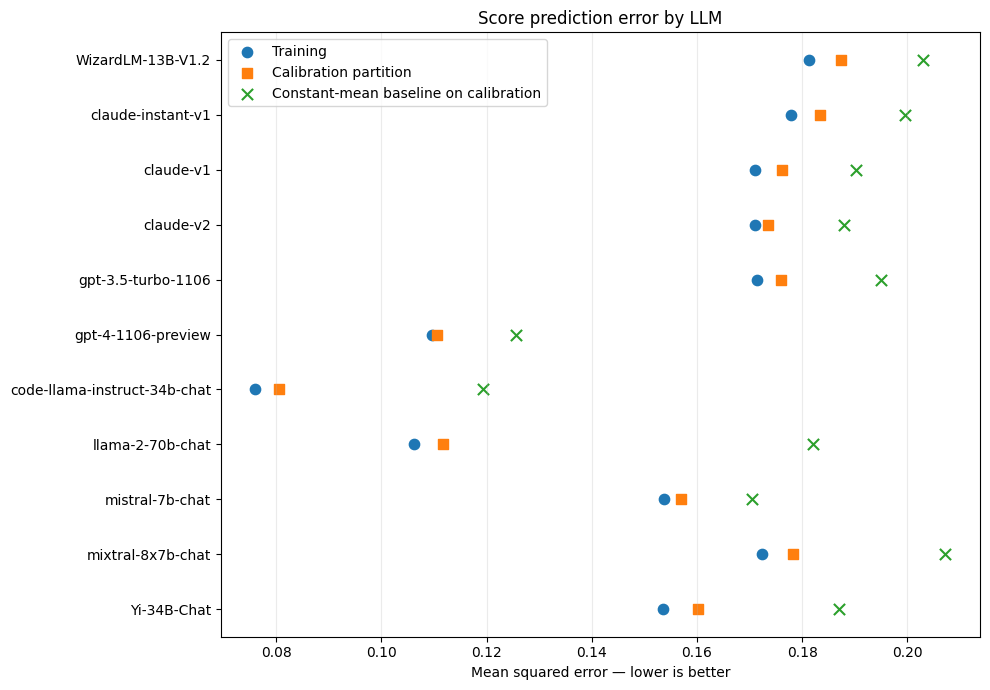

In [18]:
# error plots on the calibration set
import matplotlib.pyplot as plt
import numpy as np

diagnostics = calibration_diagnostics.copy()

# Shorten labels for display only.
names = [
    name.split("/")[-1]
    for name in diagnostics.index
]

positions = np.arange(len(names))

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(
    diagnostics["training_MSE"],
    positions,
    label="Training",
    marker="o",
    s=55,
)

ax.scatter(
    diagnostics["calibration_MSE"],
    positions,
    label="Calibration partition",
    marker="s",
    s=55,
)

ax.scatter(
    diagnostics["baseline_MSE"],
    positions,
    label="Constant-mean baseline on calibration",
    marker="x",
    s=65,
)

ax.set_yticks(positions)
ax.set_yticklabels(names)
ax.invert_yaxis()

ax.set_xlabel("Mean squared error — lower is better")
ax.set_title("Score prediction error by LLM")
ax.grid(axis="x", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [19]:
# Calculate expected-score reliability bins once for tables and plots.
bin_tables = {}

for model_name in calibration_scores.columns:
    details = pd.DataFrame({
        "predicted": calibration_predictions[model_name],
        "observed": calibration_scores[model_name],
    })

    details["bin"] = pd.qcut(
        details["predicted"],
        q=10,
        duplicates="drop",
    )

    table = (
        details.groupby("bin", observed=True)
        .agg(
            count=("observed", "size"),
            prediction_min=("predicted", "min"),
            prediction_max=("predicted", "max"),
            mean_prediction=("predicted", "mean"),
            mean_observed=("observed", "mean"),
        )
    )

    table["percent_of_prompts"] = (
        100 * table["count"] / len(details)
    )

    table["gap"] = (
        table["mean_prediction"] - table["mean_observed"]
    )

    bin_tables[model_name] = table

# Summarize all models after their bin tables have been calculated.
bin_summary = pd.DataFrame([
    {
        "LLM": name,
        "number_of_bins": len(table),
        "smallest_bin": table["count"].min(),
        "largest_bin": table["count"].max(),
        "weighted_absolute_gap": np.average(
            table["gap"].abs(),
            weights=table["count"],
        ),
        "largest_absolute_gap": table["gap"].abs().max(),
    }
    for name, table in bin_tables.items()
]).set_index("LLM")

display(
    bin_summary.sort_values(
        "weighted_absolute_gap",
        ascending=False,
    ).round(4)
)

,number_of_bins,smallest_bin,largest_bin,weighted_absolute_gap,largest_absolute_gap
LLM,,,,,
claude-v2,10,364,365,0.0380,0.1102
zero-one-ai/Yi-34B-Chat,10,364,365,0.0345,0.0547
gpt-3.5-turbo-1106,10,364,365,0.0340,0.0895
claude-instant-v1,10,364,365,0.0322,0.0947
gpt-4-1106-preview,10,364,365,0.0307,0.0463
mistralai/mixtral-8x7b-chat,10,364,365,0.0301,0.0595
claude-v1,10,364,365,0.0268,0.0731
WizardLM/WizardLM-13B-V1.2,10,364,365,0.0222,0.0866
mistralai/mistral-7b-chat,10,364,365,0.0216,0.0407


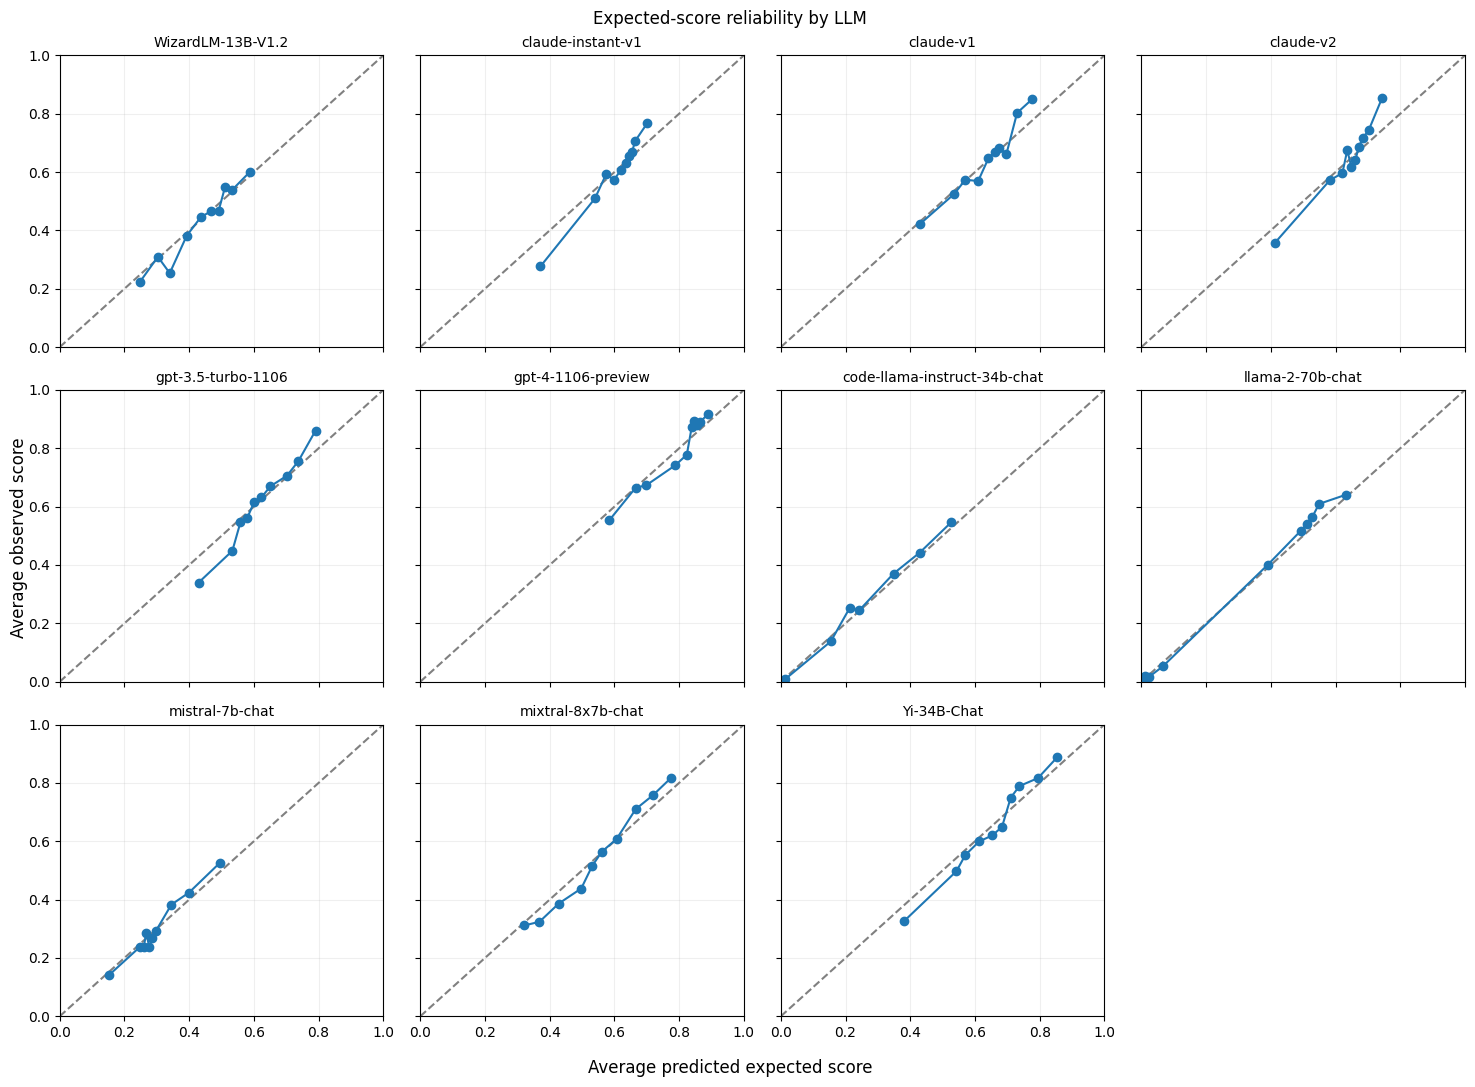

In [20]:
# Plot the expected-score reliability tables calculated above.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 4,
    figsize=(15, 11),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()

for ax, (model_name, table) in zip(axes, bin_tables.items()):
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.plot(table["mean_prediction"], table["mean_observed"], "o-")
    ax.set_title(model_name.split("/")[-1], fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)

for ax in axes[len(bin_tables):]:
    ax.set_visible(False)

fig.supxlabel("Average predicted expected score")
fig.supylabel("Average observed score")
fig.suptitle("Expected-score reliability by LLM")

plt.tight_layout()
plt.show()


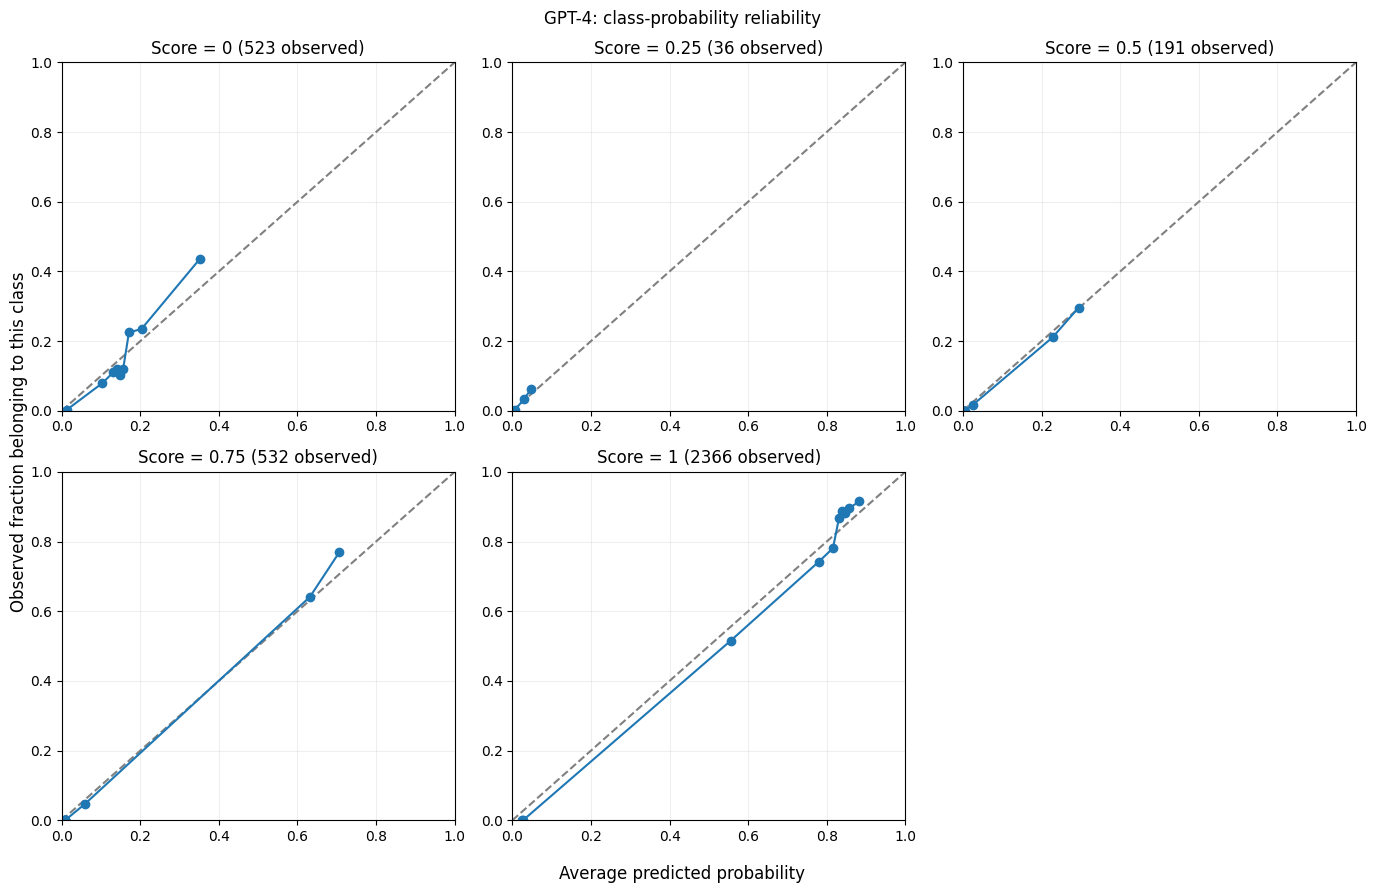

In [21]:
MODEL_NAME = "gpt-4-1106-preview"

model = loaded_models[MODEL_NAME]

probabilities = model.predict_proba(X_calibration)

observed_labels = (
    (calibration_scores[MODEL_NAME] * 4)
    .round()
    .astype(int)
    .to_numpy()
)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

class_reliability_tables = {}

for column, class_label in enumerate(model.classes_):
    score_value = metadata["score_values"][int(class_label)]

    details = pd.DataFrame({
        "probability": probabilities[:, column],

        # 1 if this prompt received this class; otherwise 0.
        "occurred": (observed_labels == class_label).astype(int),
    })

    details["bin"] = pd.qcut(
        details["probability"],
        q=10,
        duplicates="drop",
    )

    table = (
        details.groupby("bin", observed=True)
        .agg(
            count=("occurred", "size"),
            occurrences=("occurred", "sum"),
            mean_probability=("probability", "mean"),
            observed_frequency=("occurred", "mean"),
        )
    )

    class_reliability_tables[score_value] = table

    ax = axes[column]

    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.plot(
        table["mean_probability"],
        table["observed_frequency"],
        "o-",
    )

    ax.set_title(
        f"Score = {score_value:g} "
        f"({details['occurred'].sum()} observed)"
    )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.2)

axes[-1].set_visible(False)

fig.supxlabel("Average predicted probability")
fig.supylabel("Observed fraction belonging to this class")
fig.suptitle("GPT-4: class-probability reliability")

plt.tight_layout()
plt.show()

Plots don't show consistent distortion that obviously calls for calibration.

## Saving xgb-score calibration results

In [22]:
# Save XGBoost score-calibration results for sharing.
EXPORT_DIR = (
    PROJECT_DIR / "artifacts" / "score_xgb" / "calibration_results"
)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

prompt_ids = calibration_questions[
    ["sample_id", "eval_name", "question_group"]
].copy()

assert prompt_ids["sample_id"].is_unique

tables = {
    "predicted_scores": calibration_predictions,
    "observed_scores": calibration_scores,
}

for filename, table in tables.items():
    assert table.index.equals(prompt_ids.index)

    prompt_ids.join(
        table.loc[:, calibration_predictions.columns]
    ).to_csv(
        EXPORT_DIR / f"{filename}.csv",
        index=False,
    )

# Save prediction errors and expected-score reliability summaries.
calibration_diagnostics.to_csv(
    EXPORT_DIR / "diagnostics.csv",
    index_label="LLM",
)

bin_summary.to_csv(
    EXPORT_DIR / "reliability_summary.csv",
    index_label="LLM",
)

pd.concat(
    bin_tables,
    names=["LLM", "bin"],
).reset_index().to_csv(
    EXPORT_DIR / "reliability_bins.csv",
    index=False,
)

# Save the GPT-4 class-probability reliability tables.
pd.concat(
    class_reliability_tables,
    names=["score_value", "bin"],
).reset_index().to_csv(
    EXPORT_DIR / "gpt4_class_reliability_bins.csv",
    index=False,
)

# Record the model configuration used for these results.
with (EXPORT_DIR / "model_metadata.json").open("w") as file:
    json.dump(metadata, file, indent=2)

print("Saved to:", EXPORT_DIR.relative_to(PROJECT_DIR))
print("Calibration prompts:", len(prompt_ids))

Saved to: artifacts/score_xgb/calibration_results
Calibration prompts: 3648
